# Footprint diversity and explicit preparation

Preserve shape diversity instead of replacing the entire stock with rectangles. Inspect any cleanup before accepting it.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

`Footprint` represents one polygon with its holes. `GeometrySpec.from_footprint(...)` also accepts a Shapely `Polygon` or `MultiPolygon`, allowing disconnected components to become building parts without discarding them. Storeys then turn a planar outline into occupied volume.

`prepare_geometry` is exported from `epsm_core` and implemented in `epsm_core.preparation`. It returns a `GeometryPreparationResult` containing source and cleaned geometry, policy, metrics and a decision. A `GeometryPolicy` specifies tolerances in metres and fractional changes: `precision_m=0.001` is a **1 mm grid**, not a decimal-place count. `simplification_m` is a distance tolerance, not a Boolean switch.

### Figure guide — How geometry feeds compilation, physical quantities and inspection

![How geometry feeds compilation, physical quantities and inspection; reference figure from EPSM documentation](../../docs/figures/geometry-pipeline.svg)

**How to read this figure.** Trace logical openings and thermal partitions into their shared resolved geometry. Window panes acquire thermal parents without changing the original logical opening. Notice that context reaches shading and preview but not physical material quantities. These are conceptual dependencies, not the chronological order of Python calls.

*Source: [EPSM architecture documentation](../../docs/architecture.md); [open the original figure](../../docs/figures/geometry-pipeline.svg).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Construct contrasting forms

Concavity, courtyard holes and disconnected components change exposed perimeter and solar access. Coordinates must already be in metres; source_crs is metadata and does not reproject them.

### Read the code and output

The equal-area assertion multiplies footprint area by two storeys. Holes remove floor area; disconnected pieces contribute their own areas. Compare the gallery's exposed perimeter as well as area: two equal-area footprints can have very different wall exposure. `plans()` only plots these shapes and performs no geometry preparation itself.

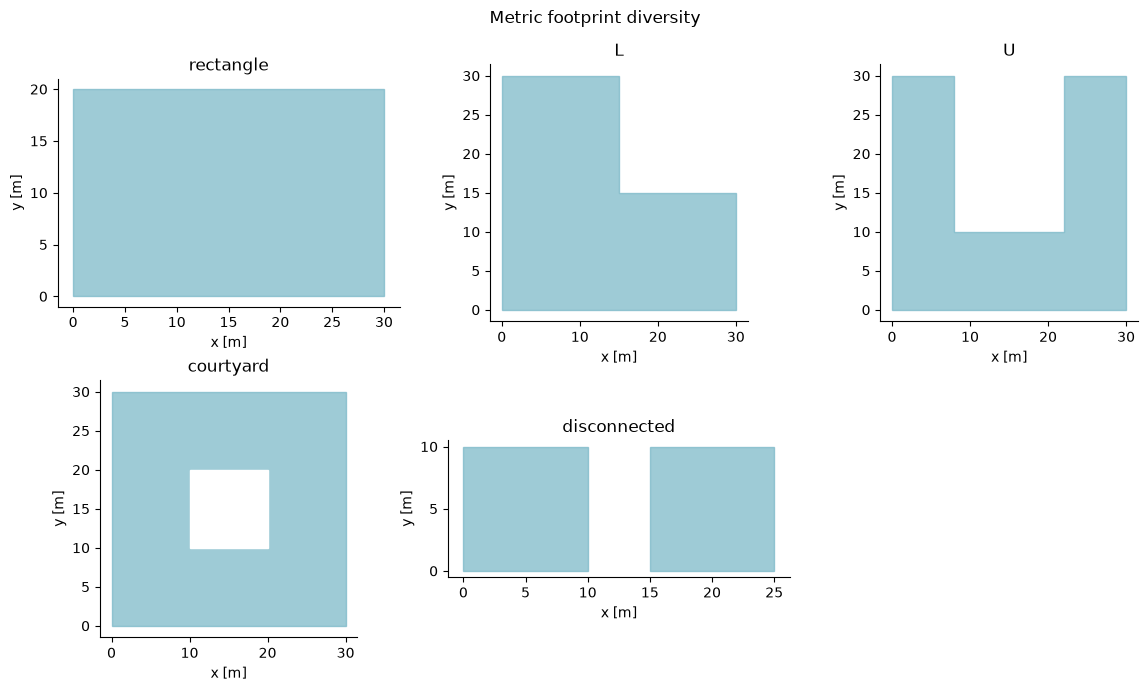

,form,parts,area_m2
0,rectangle,1,600.0
1,L,1,675.0
2,U,1,620.0
3,courtyard,1,800.0
4,disconnected,2,200.0


In [2]:
from shapely.geometry import Polygon, MultiPolygon, box, shape
forms = {"rectangle": Footprint.rectangle(30,20),
         "L": Footprint.l_shape(30,30,15,15),
         "U": Footprint.u_shape(30,30,14,20),
         "courtyard": box(0,0,30,30).difference(box(10,10,20,20)),
         "disconnected": MultiPolygon([box(0,0,10,10), box(15,0,25,10)])}
# Use the common demo function plans to plot the forms
plans(forms)
rows = []
for name, outline in forms.items():
    g = GeometrySpec.from_footprint(outline, storeys=2, storey_height_m=3)
    assert np.isclose(g.conditioned_floor_area_m2, 2*g.footprint_area_m2)
    rows.append({"form": name, "parts": len(g.parts), "area_m2": g.footprint_area_m2})
t_footprint_forms = table(rows)

## Audit a real repository footprint

This deterministic corpus selection exercises a real outline; it does not establish a representative sample. The fixture retains source and cleaned geometries. Roof-edge proxies still need interpretation before becoming facade footprints.

### Read the code and output

The fixtures live in this repository under `tests/fixtures`, not in a national database shipped with the wheel. `shape(...)` decodes their GeoJSON-like geometry. Inspect `prepared.status` and `reasons` before using `cleaned_geometry`; saving an artifact records the decision but does not approve it. The source CRS label records a metric coordinate system already supplied by the caller.

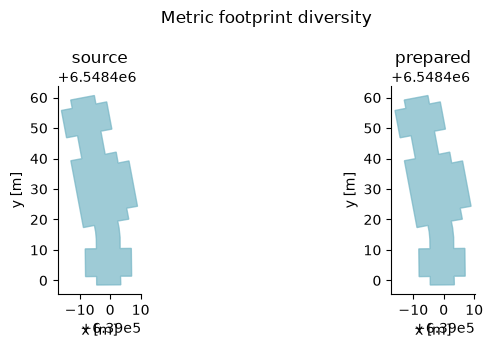

,field,value
0,fixture,0181-000338b8-c89a-45e2-93f5-f697c11fa8dc.json
1,status,accepted
2,reasons,()
3,boundary_displacement_m,9.313225746154785e-10
4,area_change_fraction,4.076061864644959e-16
5,perimeter_change_fraction,2.9674427565989954e-16
6,source_area_m2,836.7402764986144
7,cleaned_area_m2,836.7402764986141
8,source_perimeter_m,191.55691793683195
9,cleaned_perimeter_m,191.5569179368319


16565

In [3]:
files = sorted((ROOT / "tests/fixtures/footprints").glob("0181-*.json"))

# This repository includes footprint fixtures under tests/fixtures for geometry checks.
# The 0181-*.json files are a set of footprints that have been used in the past to test the geometry preparation code. 
# The following code will load the first fixture, prepare it, and then save the prepared geometry to a new file.
fixture = json.loads(files[0].read_text())

# shape is a function imported from shapely.geometry that converts a GeoJSON-like dict into a Shapely geometry object.
raw = shape(fixture["source_geometry"])

# prepare_geometry is exported by epsm_core and implemented in epsm_core.preparation.
# It takes a Shapely geometry and a GeometryPolicy object as input and returns a GeometryPreparationResult object.

# What is a GeometryPolicy? It is a class that defines the rules for how to prepare a geometry.
# It includes rules such as:
# precision_m: coordinate grid spacing in metres (0.001 m is a 1 mm grid).
# simplification_m: distance tolerance in metres for simplifying the outline.
# max_displacement_m: the permitted boundary displacement; area and perimeter limits are separate.

# It might feel tedious to define a GeometryPolicy for every geometry preparation task. 
# The returned GeometryPreparationResult is useful because it contains information
# about the preparation process, such as whether the geometry was valid, 
# whether it was simplified, and any reasons for why the geometry was modified.
# and also retains the original geometry for reference.

prepared = prepare_geometry(raw, GeometryPolicy())
assert isinstance(prepared, GeometryPreparationResult)
plans({"source": raw, "prepared": prepared.cleaned_geometry})
table({"fixture": files[0].name, "status": prepared.status, "reasons": prepared.reasons, **prepared.metrics})
artifact = prepared.artifact(source_crs="EPSG:3006", target_crs="EPSG:3006", transformation="none; already metric")
(OUT / "preparation.json").write_text(json.dumps(artifact, indent=2))

## Keep review decisions visible

A self-intersecting polygon is deliberately supplied to preparation, not directly accepted as a Footprint. Repair is evidence to review, not an automatic endorsement.

### Read the code and output

The bowtie crosses itself, making it a useful deliberately invalid source example. A repaired polygon can be mathematically valid while its intended physical outline is ambiguous. That is why the assertion expects a review or rejection decision. In a stock pipeline, count these records separately instead of quietly excluding them from the denominator.

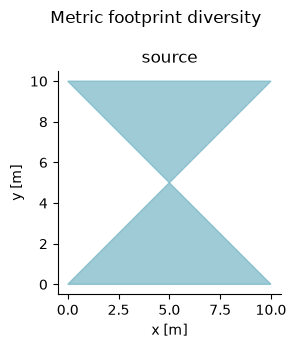

,field,value
0,status,needs_review
1,reasons,"('area_change_fraction_exceeded', 'topology_ch..."


In [4]:
bowtie = Polygon([(0,0),(10,10),(0,10),(10,0)])
# Plot the bowtie shape using the common demo function plan
plans({"source": bowtie})
# Pass it to the prepare_geometry function to see how it handles the bowtie shape.
review = prepare_geometry(bowtie)
assert review.status != "accepted"
t_bowtie_review = table({"status": review.status, "reasons": review.reasons})

## Interpretation and next experiment

Compare area, perimeter and topology before and after preparation. Quantify how many source records require review rather than hiding their loss from the stock sample.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.